# EDA: что добавляют features к названию товара

Сравниваем `title` и `title + features` на 2000 товарах Grocery. Вопрос: меняются ли смысловые соседи и стоит ли добавлять характеристики в текст для CLIP?

В `graphic_eda_fashion` уже разобрана заполненность характеристик; в `eda_images` есть эмбеддинги названий. Здесь проверяем именно добавление текста. Модель та же: ViT-B/32, `laion2b_s34b_b79k`. Отзывы, картинки и пользовательские истории не нужны.

Запуск из корня проекта: `python scripts/prepare_text_features_sample.py`, затем этот ноутбук в окружении с `open-clip-torch`, `torch`, `pandas`, `pyarrow`, `numpy`, `matplotlib`. Ревизия данных и версии библиотек сохраняются в `reports/eda_text_features_config.csv`. Для HTML: `jupyter nbconvert --to html notebooks/eda_text_features.ipynb --output-dir reports`.

In [1]:
import hashlib
import json
import os
import re
import sys
import warnings
from collections import Counter
from importlib.metadata import version
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "pyproject.toml").exists() else Path.cwd().parent
CACHE = ROOT / "data/cache/text_features"
REPORTS = ROOT / "reports"
os.environ.setdefault("HF_HOME", str(ROOT / "data/cache/huggingface"))
os.environ.setdefault("MPLCONFIGDIR", str(CACHE / "matplotlib"))

warnings.filterwarnings("ignore", message="IProgress not found.*")

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import open_clip
import pandas as pd
import torch
from huggingface_hub import hf_hub_download
from IPython.display import display

SEED, K = 42, 10
MODEL, PRETRAINED = "ViT-B-32", "laion2b_s34b_b79k"
CATEGORY = "Grocery_and_Gourmet_Food"
DEVICE = os.environ.get("TEXT_FEATURES_DEVICE", "cpu")
torch.manual_seed(SEED)
torch.set_num_threads(4)
plt.rcParams.update({"figure.figsize": (9, 4), "font.size": 10})
pd.set_option("display.max_colwidth", 85)

items = (
    pd.read_parquet(CACHE / "sample.parquet")
    .sort_values("parent_asin")
    .reset_index(drop=True)
)
assert items.parent_asin.is_unique and len(items) > K
config = dict(pd.read_csv(CACHE / "source_config.csv", dtype=str).values)
assert (
    hashlib.sha256((CACHE / "sample.parquet").read_bytes()).hexdigest()
    == config["sample_parquet_sha256"]
)
assert (
    hashlib.sha256("\n".join(items.parent_asin).encode()).hexdigest()
    == config["sample_ids_sha256"]
)
assert len(items) == int(config["sample_size"])
source_audit = pd.read_csv(CACHE / "source_audit.csv", keep_default_na=False)
print(f"{len(items)} товаров; устройство: {DEVICE}")
display(source_audit.query("section == 'source'")[["metric", "value"]])

2000 товаров; устройство: cpu


,metric,value
0,duplicate_eligible_id,0
1,eligible_unique,435823
2,features_non_list,0
3,invalid_json,0
4,invalid_record,0
5,missing_features,167413
6,missing_id,0
7,missing_title,38
8,source_rows,603274


## Выборка

Одна строка — карточка `parent_asin`. Источник: публичные метаданные Amazon Reviews 2023; совпадение с командным S3 не проверяли. Отбор равномерный по всем уникальным товарам с непустыми `title` и `features`, seed=42. Весь файл проверяется по SHA256.

Меткой служит `categories[1]`. Это широкий и местами шумный уровень каталога. Метки и магазин не входят в текст энкодера. Товары без меток остаются в поиске, но исключаются из знаменателя метрики совпадения категории. Выводы относятся только к товарам с характеристиками.

In [3]:
coverage = (
    source_audit.query("section == 'label_coverage'")
    .pivot(index="group", columns="metric", values="value")
    .fillna(0)
)
coverage["eligible_share"] = coverage.eligible_count / coverage.eligible_count.sum()
coverage["sample_share"] = coverage.sample_count / len(items)
coverage["difference_pp"] = 100 * (coverage.sample_share - coverage.eligible_share)
display(coverage.sort_values("eligible_count", ascending=False).head(12).round(3))
print(f"Без метки: {items.label.eq('').sum()} из {len(items)}")

metric,eligible_count,sample_count,eligible_share,sample_share,difference_pp
group,,,,,
Pantry Staples,165435,751,0.380,0.376,-0.409
Snacks & Sweets,85464,400,0.196,0.200,0.390
Beverages,75558,374,0.173,0.187,1.363
Breads & Bakery,20817,95,0.048,0.048,-0.026
missing,12840,47,0.029,0.024,-0.596
Produce,10197,31,0.023,0.016,-0.790
"Dairy, Eggs & Plant-Based Alternatives",9718,47,0.022,0.024,0.120
Food & Beverage Gifts,9702,52,0.022,0.026,0.374
Frozen,8360,37,0.019,0.018,-0.068


Без метки: 47 из 2000


## Текст и лимит CLIP

Склеиваем название и характеристики через ` | `, сохраняя порядок пунктов. Только нормализуем пробелы. В CLIP помещаются 75 содержательных токенов плюс два служебных. Считаем, сколько текста характеристик действительно доходит до модели.

,metric,value
0,n_features_median,5.000
1,title_words_median,11.000
2,features_words_median,42.000
3,title_tokens_median,18.000
4,combined_tokens_median,76.000
5,title_truncated_share,0.002
6,combined_truncated_share,0.501
7,features_visible_tokens_median,40.000
8,features_visible_share_mean,0.720
9,no_features_visible_share,0.002


,feature,items
0,gluten free,47
1,kosher,25
2,all natural,16
3,"no hydrogenated fats, high-fructose corn syrup or added msg",16
4,no hydrogenated fats or high fructose corn syrup allowed in any food,15
5,no bleached or bromated flour,15
6,no synthetic nitrates or nitrites,13
7,this item is typically available for pickup/delivery between 10am-6pm,13


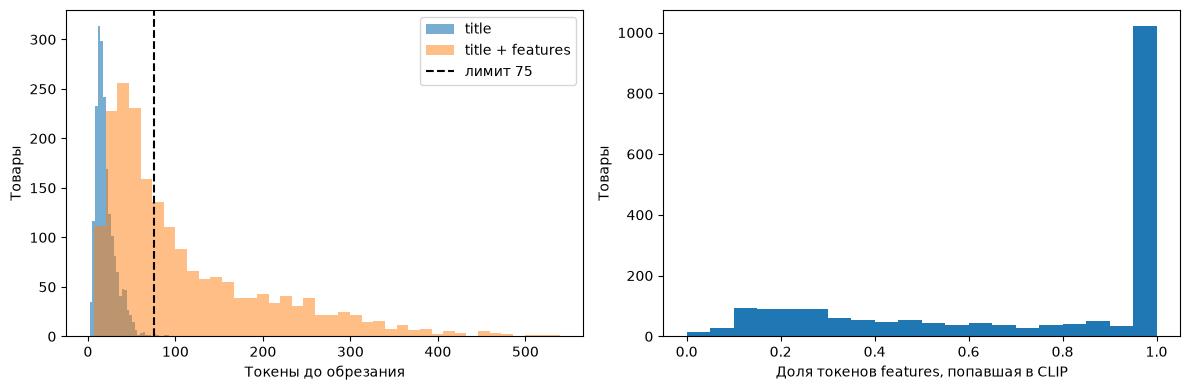

In [4]:
tokenizer = open_clip.get_tokenizer(MODEL)
assert hasattr(tokenizer, "encode") and tokenizer.context_length == 77
LIMIT = tokenizer.context_length - 2
items["features_text"] = items.features.map(lambda x: " ".join(x))
items["combined"] = items.title + " | " + items.features_text
items["n_features"] = items.features.map(len)
title_ids = [tokenizer.encode(x) for x in items.title]
combined_ids = [tokenizer.encode(x) for x in items.combined]
prefix_ids = [tokenizer.encode(x + " | ") for x in items.title]
assert all(c[: len(p)] == p for c, p in zip(combined_ids, prefix_ids, strict=True))
items["title_tokens"] = list(map(len, title_ids))
items["combined_tokens"] = list(map(len, combined_ids))
items["features_tokens"] = [
    len(c) - len(p) for c, p in zip(combined_ids, prefix_ids, strict=True)
]
items["features_visible_tokens"] = [
    max(0, min(len(c), LIMIT) - len(p))
    for c, p in zip(combined_ids, prefix_ids, strict=True)
]
items["features_visible_share"] = (
    items.features_visible_tokens / items.features_tokens.replace(0, np.nan)
)
items["title_truncated"] = items.title_tokens > LIMIT
items["combined_truncated"] = items.combined_tokens > LIMIT


def norm(text):
    return " ".join(text.casefold().split())


def words(text):
    return set(re.findall(r"\w+", text.casefold()))


items["new_words_share"] = [
    len(words(f) - words(t)) / max(1, len(words(f)))
    for t, f in zip(items.title, items.features_text, strict=True)
]
items["repeats_title"] = [
    any(norm(f) == norm(t) for f in fs)
    for t, fs in zip(items.title, items.features, strict=True)
]
feature_frequency = Counter(f for fs in items.features for f in {norm(x) for x in fs})
items["common_feature"] = items.features.map(
    lambda fs: any(feature_frequency[norm(f)] >= 10 for f in fs)
)
items["html_fragment"] = items.combined.str.contains(
    r"<[^>]+>|&(?:amp|lt|gt|nbsp);", regex=True
)
audit_values = {
    "n_features_median": items.n_features.median(),
    "title_words_median": items.title.str.split().str.len().median(),
    "features_words_median": items.features_text.str.split().str.len().median(),
    "title_tokens_median": items.title_tokens.median(),
    "combined_tokens_median": items.combined_tokens.median(),
    "title_truncated_share": items.title_truncated.mean(),
    "combined_truncated_share": items.combined_truncated.mean(),
    "features_visible_tokens_median": items.features_visible_tokens.median(),
    "features_visible_share_mean": items.features_visible_share.mean(),
    "no_features_visible_share": items.features_visible_tokens.eq(0).mean(),
    "feature_repeats_title_share": items.repeats_title.mean(),
    "common_feature_10_items_share": items.common_feature.mean(),
    "html_fragment_share": items.html_fragment.mean(),
    "new_words_share_mean": items.new_words_share.mean(),
    "missing_label_share": items.label.eq("").mean(),
}
audit = pd.DataFrame(
    [
        dict(
            section="sample",
            metric=k,
            group="all",
            value=v,
            n=len(items),
            category=CATEGORY,
        )
        for k, v in audit_values.items()
    ]
)
pd.concat([source_audit, audit], ignore_index=True).to_csv(
    REPORTS / "eda_text_features_audit.csv", index=False
)
display(audit[["metric", "value"]].round(3))
display(pd.DataFrame(feature_frequency.most_common(8), columns=["feature", "items"]))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(items.title_tokens, bins=30, alpha=0.6, label="title")
axes[0].hist(items.combined_tokens, bins=40, alpha=0.5, label="title + features")
axes[0].axvline(LIMIT, color="black", linestyle="--", label="лимит 75")
axes[0].set(xlabel="Токены до обрезания", ylabel="Товары")
axes[0].legend()
axes[1].hist(items.features_visible_share.dropna(), bins=20)
axes[1].set(xlabel="Доля токенов features, попавшая в CLIP", ylabel="Товары")
plt.tight_layout()
plt.show()

## Два представления, один поиск

Нормированные эмбеддинги, обычный косинус, top-10 без самого товара. Для обоих вариантов совпадают запросы и каталог из 2000 товаров. При равных скорах порядок задаёт `parent_asin`. Ничего не обучаем на этой выборке.

Основная метрика — средняя по запросам доля соседей той же подкатегории. Дополнительно: пересечение списков и одинаковые названия у соседей. Это диагностика смыслового поиска, а не Recall/NDCG персональных рекомендаций. Числа из `eda_images` напрямую несопоставимы: там другая выборка и центрирование.

In [5]:
weights = CACHE / "weights"
MODEL_REPO = "laion/CLIP-ViT-B-32-laion2B-s34B-b79K"
MODEL_REVISION = "1a25a446712ba5ee05982a381eed697ef9b435cf"
EXPECTED_WEIGHT_HASH = (
    "ac4f8c4b88af6d963118cbf40ad93176d092abbedfcb752601ae1866352656e6"
)
weight_path = Path(
    hf_hub_download(
        repo_id=MODEL_REPO,
        filename="open_clip_model.safetensors",
        revision=MODEL_REVISION,
        cache_dir=str(weights),
    )
)


def file_hash(path):
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


weight_hashes = [file_hash(weight_path)]
assert weight_hashes == [EXPECTED_WEIGHT_HASH]
model, _, _ = open_clip.create_model_and_transforms(
    MODEL,
    pretrained=str(weight_path),
    device=DEVICE,
)
model.eval()
config.update({"model_repository": MODEL_REPO, "model_revision": MODEL_REVISION})
config.update(
    {
        "model": MODEL,
        "pretrained": PRETRAINED,
        "device": DEVICE,
        "weight_sha256": json.dumps(weight_hashes),
        "k": K,
        "context_length": tokenizer.context_length,
        "text_separator_json": json.dumps(" | "),
        "similarity": "cosine, L2 normalized, no centering",
        "self_match": "excluded",
        "tie_break": "parent_asin ascending",
        "python": sys.version.split()[0],
    }
)
for package in [
    "open-clip-torch",
    "torch",
    "torchvision",
    "numpy",
    "pandas",
    "pyarrow",
    "matplotlib",
    "nbformat",
    "nbclient",
    "nbconvert",
    "requests",
    "huggingface-hub",
]:
    config["version_" + package] = version(package)


@torch.inference_mode()
def embed(texts, name):
    fingerprint = hashlib.sha256(
        json.dumps(
            {
                "texts": texts,
                "model": MODEL,
                "pretrained": PRETRAINED,
                "weights": weight_hashes,
                "context": tokenizer.context_length,
                "device": DEVICE,
                "torch": version("torch"),
                "open_clip": version("open-clip-torch"),
            },
            sort_keys=True,
        ).encode()
    ).hexdigest()
    path = CACHE / f"{name}_embeddings.npz"
    if path.exists():
        with np.load(path) as saved:
            if str(saved["fingerprint"]) == fingerprint and np.array_equal(
                saved["ids"], items.parent_asin.to_numpy()
            ):
                print(name, "из кеша")
                return saved["embeddings"].copy()
    chunks = []
    for start in range(0, len(texts), 64):
        tokens = tokenizer(texts[start : start + 64]).to(DEVICE)
        emb = model.encode_text(tokens).float()
        chunks.append(torch.nn.functional.normalize(emb, dim=-1).cpu().numpy())
    result = np.concatenate(chunks).astype(np.float32)
    np.savez(
        path,
        embeddings=result,
        ids=items.parent_asin.to_numpy(dtype=str),
        fingerprint=fingerprint,
    )
    print(name, result.shape)
    return result


vectors = {
    "title": embed(items.title.tolist(), "title"),
    "title_features": embed(items.combined.tolist(), "title_features"),
}
neighbors = {}
for name, matrix in vectors.items():
    assert matrix.shape == (len(items), 512) and np.isfinite(matrix).all()
    assert np.allclose(np.linalg.norm(matrix, axis=1), 1, atol=1e-5)
    scores = matrix @ matrix.T
    np.fill_diagonal(scores, -np.inf)
    neighbors[name] = np.argsort(-scores, axis=1, kind="stable")[:, :K]
    assert not (neighbors[name] == np.arange(len(items))[:, None]).any()
    assert all(len(set(row)) == K for row in neighbors[name])
    # Прямая проверка порядка на трёх запросах.
    for i in [0, len(items) // 2, len(items) - 1]:
        expected = sorted(
            (j for j in range(len(items)) if j != i),
            key=lambda j: (-float(scores[i, j]), items.parent_asin.iloc[j]),
        )[:K]
        assert neighbors[name][i].tolist() == expected
pd.DataFrame(config.items(), columns=["parameter", "value"]).to_csv(
    REPORTS / "eda_text_features_config.csv", index=False
)

title из кеша
title_features из кеша


,metric,variant,value,n
0,category_purity,title,0.6554,1953
1,same_title_share,title,0.0000,2000
2,valid_neighbors_mean,title,9.8054,1953
3,category_purity,title_features,0.6707,1953
4,same_title_share,title_features,0.0000,2000
5,valid_neighbors_mean,title_features,9.8223,1953
6,category_purity,random_expected,0.2312,1953
7,category_purity_delta,title_features_minus_title,0.0153,1953
8,top10_overlap,both,0.6094,2000


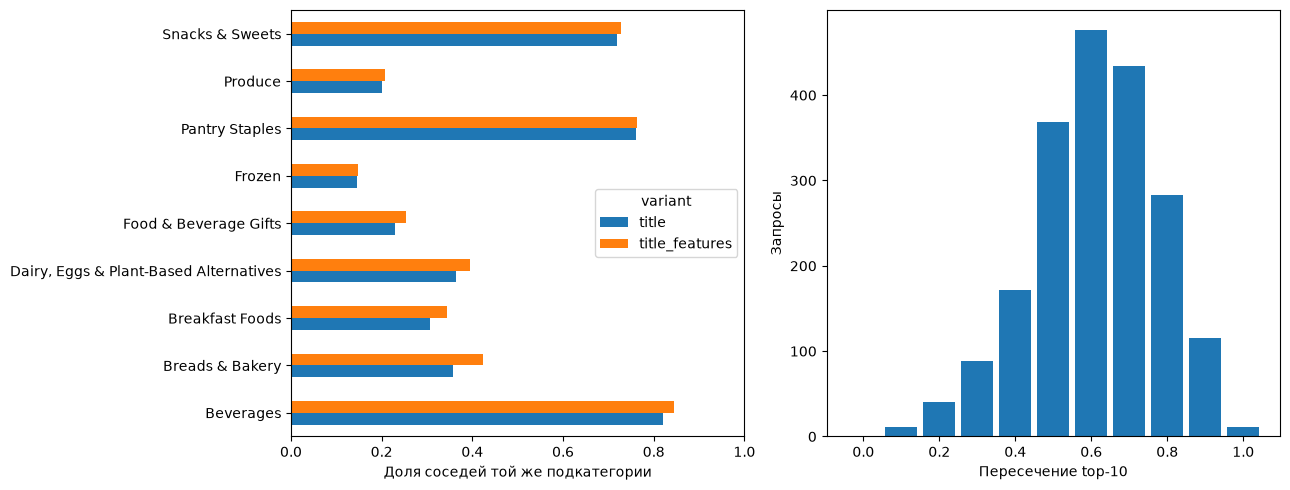

In [6]:
labels = items.label.to_numpy()
valid_queries = labels != ""
normalized_titles = items.title.map(norm).to_numpy()
per_query = pd.DataFrame({"parent_asin": items.parent_asin, "label": labels})
for name, idx in neighbors.items():
    neighbor_labels = labels[idx]
    valid_pairs = valid_queries[:, None] & (neighbor_labels != "")
    denominator = valid_pairs.sum(axis=1)
    same = ((neighbor_labels == labels[:, None]) & valid_pairs).sum(axis=1)
    per_query[name + "_purity"] = np.divide(
        same, denominator, out=np.full(len(items), np.nan), where=denominator > 0
    )
    per_query[name + "_valid_neighbors"] = denominator
    per_query[name + "_same_title"] = (
        normalized_titles[idx] == normalized_titles[:, None]
    ).mean(axis=1)
per_query["overlap"] = [
    len(set(a) & set(b)) / K
    for a, b in zip(neighbors["title"], neighbors["title_features"], strict=True)
]
common_queries = (
    per_query[["title_purity", "title_features_purity"]].notna().all(axis=1)
)
per_query["purity_delta"] = per_query.title_features_purity - per_query.title_purity
label_sizes = Counter(labels[valid_queries])
per_query["random_purity"] = [
    ((label_sizes[x] - 1) / (valid_queries.sum() - 1)) if x else np.nan for x in labels
]

metric_rows = []


def record(metric, variant, group, values):
    values = pd.Series(values).dropna()
    metric_rows.append(
        dict(
            category=CATEGORY,
            metric=metric,
            variant=variant,
            group=group,
            value=values.mean(),
            n=len(values),
            k=K,
        )
    )


for name in neighbors:
    record(
        "category_purity", name, "all", per_query.loc[common_queries, name + "_purity"]
    )
    record("same_title_share", name, "all", per_query[name + "_same_title"])
    record(
        "valid_neighbors_mean",
        name,
        "all",
        per_query.loc[common_queries, name + "_valid_neighbors"],
    )
record(
    "category_purity",
    "random_expected",
    "all",
    per_query.loc[common_queries, "random_purity"],
)
record(
    "category_purity_delta",
    "title_features_minus_title",
    "all",
    per_query.loc[common_queries, "purity_delta"],
)
record("top10_overlap", "both", "all", per_query.overlap)
for label, count in items.label.value_counts().items():
    if label and count >= 30:
        mask = common_queries & items.label.eq(label)
        for name in neighbors:
            record(
                "category_purity",
                name,
                "label:" + label,
                per_query.loc[mask, name + "_purity"],
            )
for group, mask in {
    "combined_fits": ~items.combined_truncated,
    "combined_truncated": items.combined_truncated,
}.items():
    for name in neighbors:
        record(
            "category_purity",
            name,
            group,
            per_query.loc[common_queries & mask, name + "_purity"],
        )
    record("top10_overlap", "both", group, per_query.loc[mask, "overlap"])
metrics = pd.DataFrame(metric_rows)
metrics.to_csv(REPORTS / "eda_text_features_metrics.csv", index=False)
per_query.to_csv(CACHE / "per_query.csv", index=False)
np.savez(CACHE / "neighbors.npz", **neighbors)
display(metrics.query("group == 'all'")[["metric", "variant", "value", "n"]].round(4))

by_label = metrics[metrics.group.str.startswith("label:")].pivot(
    index="group", columns="variant", values="value"
)
by_label.index = by_label.index.str.removeprefix("label:")
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
by_label.plot.barh(ax=axes[0], xlim=(0, 1))
axes[0].set(xlabel="Доля соседей той же подкатегории", ylabel="")
axes[1].hist(per_query.overlap, bins=np.arange(-0.05, 1.1, 0.1), rwidth=0.85)
axes[1].set(xlabel="Пересечение top-10", ylabel="Запросы")
plt.tight_layout()
plt.show()

С характеристиками доля соседей той же подкатегории выросла с **65,54% до 67,07%** (+1,53 п.п.; 1953 запроса с метками). Для случайных соседей ожидается 23,12%. В top-10 совпадает в среднем **6,09 товара**.

Из крупных групп заметнее изменение у напитков: 82,14% → 84,56%. У Pantry Staples почти без изменений: 76,11% → 76,26%. Это описательные различия на одной выборке, без проверки статистической значимости.

## Примеры

До просмотра результатов выбираем 30 запросов с seed=42. Для каждого сохраняем объединение top-3 двух вариантов, не более 180 пар. Для слепой проверки ниже скрыты источник и ранги.

Рубрика: тот же тип/назначение; совместимость явно указанных свойств; явное противоречие; недостаточно информации. Совпадение вкуса или бренда само по себе не делает товары взаимозаменяемыми. Проверка человеком отмечается отдельно от просмотра Codex; незаполненные оценки не считаются отрицательными.

In [7]:
query_indices = np.random.default_rng(SEED).choice(
    len(items), size=min(30, len(items)), replace=False
)
example_rows = []
for order, i in enumerate(query_indices, start=1):
    ranks = {
        name: {int(j): rank + 1 for rank, j in enumerate(idx[i, :3])}
        for name, idx in neighbors.items()
    }
    candidates = sorted(set(ranks["title"]) | set(ranks["title_features"]))
    for j in candidates:
        example_rows.append(
            {
                "query_order": order,
                "query_id": items.parent_asin.iloc[i],
                "candidate_id": items.parent_asin.iloc[j],
                "query_title": items.title.iloc[i],
                "query_features": items.features_text.iloc[i],
                "candidate_title": items.title.iloc[j],
                "candidate_features": items.features_text.iloc[j],
                "query_label": items.label.iloc[i],
                "candidate_label": items.label.iloc[j],
                "rank_title": ranks["title"].get(j),
                "rank_title_features": ranks["title_features"].get(j),
                "review_status": "pending",
                "review_source": "",
                "same_type": "",
                "properties": "",
                "review_note": "",
                "human_review_status": "pending",
                "category": CATEGORY,
            }
        )
examples = (
    pd.DataFrame(example_rows).sample(frac=1, random_state=SEED).reset_index(drop=True)
)
examples_path = REPORTS / "eda_text_features_examples.csv"
review_columns = [
    "review_status",
    "review_source",
    "same_type",
    "properties",
    "review_note",
    "human_review_status",
]
if examples_path.exists():
    old = pd.read_csv(examples_path, keep_default_na=False)
    # Не теряем проверку при повторном запуске; связываем и по ID, и по тексту.
    keys = [
        "query_id",
        "candidate_id",
        "query_title",
        "query_features",
        "candidate_title",
        "candidate_features",
    ]
    assert not old.duplicated(keys).any()
    saved = old.set_index(keys)
    for idx, row in examples.iterrows():
        key = tuple(row[k] for k in keys)
        if key in saved.index:
            for col in review_columns:
                examples.at[idx, col] = saved.loc[key, col]
examples.to_csv(examples_path, index=False)
blind = examples[
    [
        "query_order",
        "query_id",
        "candidate_id",
        "query_title",
        "query_features",
        "candidate_title",
        "candidate_features",
    ]
]
print(f"{len(query_indices)} запросов, {len(examples)} пар")
print("Проверено человеком:", examples.human_review_status.eq("done").sum())
display(blind.head(6))
config.update(
    {
        "example_queries": len(query_indices),
        "example_pairs": len(examples),
        "codex_reviewed_pairs": examples.review_source.eq("Codex").sum(),
        "human_reviewed_pairs": examples.human_review_status.eq("done").sum(),
    }
)
pd.DataFrame(config.items(), columns=["parameter", "value"]).to_csv(
    REPORTS / "eda_text_features_config.csv", index=False
)

30 запросов, 126 пар
Проверено человеком: 0


,query_order,query_id,candidate_id,query_title,query_features,candidate_title,candidate_features
0,19,B01HY46CVU,B06XNP38BW,Macarons de Pauline Pistachio Macarons,"Sweet french delight: 6 Macarons, filled with delicious almond pistachio cream. O...",Bonbons OBLIBON Chocolate (30 Units),Chocolate Bombons Peanut Butter Box of 30 units
1,6,B00393BDAG,B001E111BG,"Full Circle Organic Tea, Green Tea, 20 Tea Bags (Pack of 3)",20 Tea Bags Package of 3 100% Pure USDA Organic 20 Tea Bags Quality packed in a f...,"Uncle Lee's Tea Legends of China Green Tea, 100 Tea Bags (Pack of 3)",Tea bags individually wrapped 100% Organic green tea leaves Full of health promot...
2,28,B07S763H38,B09G8ZVHMW,Original Stevia Drops by Good Good (1.69 Fl oz / 50ml) - Sugar Free Substitute an...,Natural Sweetener Stevia Drops And Perfect Sugar Free Substitute From The Leaves ...,"Pyure Organic Powdered Confectioners Stevia Sweetener Blend, 2:1 Sugar Substitute...","POWDERED CONFECTIONARY SWEETENER- Pyure offers the same taste, feel and ease of u..."
3,18,B088PQNMRL,B01N0E33YP,Ethiopia Yirgacheffe Coffee - Ground Coffee - Freshly Roasted Coffee - Cubico Cof...,100% Ethiopia Yirgacheffe Coffee - grown on the sloping hills of the Yirgachaffe ...,"Nicaragua Matagalpa Catimor Arabica, Green Unroasted Coffee Beans (3 lb)",Rare heirloom Arabica variety prized for superb taste profile in light roasts Lar...
4,23,B06X1GKJTR,B08DF2342X,"Golden Natural Crunchy Rice Sticks, Guilt-Free 8-Sticks, 4 Count","Rice sticks, 8-sticks, box of 4 bags (total 32 sticks) All natural, gluten free, ...","KIND Oatmeal, Oats & Almond, Gluten Free, Low Sugar, Individual Packets, 30 Count","Contains (30) individually wrapped packets of KIND Oatmeal, Oats & Almond Gluten ..."
5,20,B01MV13U8M,B07RGXTFXP,Gormly's Buttermilk Pancake Mix - 24 Ounce Bag (2 Pack),Fresh-milled flour and real buttermilk Fluffy and moist texture Just the right ta...,"All Natural Buttermilk Pancake and Waffle Mix by Birch Benders, Made with Real Sw...",6-Pack of 24oz pouches - feeds a crowd! Makes 240 four-inch pancakes or waffles. ...


In [8]:
reviewed = examples.query("review_status == 'reviewed'").sort_values(
    ["query_order", "candidate_id"]
)
display(
    reviewed[
        [
            "query_order",
            "candidate_id",
            "rank_title",
            "rank_title_features",
            "same_type",
            "properties",
            "review_note",
        ]
    ]
)

,query_order,candidate_id,rank_title,rank_title_features,same_type,properties,review_note
23,1,B078HL6K4Y,1.0,3.0,partial,contradiction,"Зелёный чай с мёдом вместо травяного. В названии есть кофеин, в features написано..."
105,1,B0BQ442LSC,3.0,2.0,yes,different,"Травяной чай без кофеина, но другой состав; ежевики и мяты в перечне нет."
108,1,B0BSLF72W2,2.0,1.0,partial,different,"Набор разных чаёв, включая зелёный и чёрный; не один травяной чай с ежевикой и мя..."
71,2,B015FZ2L2O,NaN,2.0,yes,different,"Украшение для годовщины, но серебристое вместо золотого и белого; нет указания на..."
10,2,B07P2L44HX,1.0,NaN,yes,contradiction,Украшение на 10 лет вместо 50.
52,2,B082S6WQYJ,3.0,3.0,yes,contradiction,Украшение на 30 лет вместо 50.
76,2,B0971CHZ31,2.0,1.0,yes,contradiction,В названии украшение на 80 лет вместо 50; общие слова в features это не исправляют.
62,3,B01J67B80I,1.0,NaN,no,different,"Сушёное манго, а запрос — апельсиновые желейные конфеты."
68,3,B01N0YC072,3.0,1.0,yes,compatible,Желейные конфеты с апельсиновым вкусом; другая форма и фасовка.
44,3,B0B2X7FM7G,NaN,2.0,yes,different,"Желейные конфеты в сахаре, но персиковые вместо апельсиновых."


## Что видно на примерах

Просмотрены первые 6 запросов из случайной выборки: 23 пары. Оценки и пояснения в CSV сделаны Codex по полным текстам карточек; человеческой разметки пока нет. Остальные 103 пары оставлены без оценок. Эти примеры объясняют изменения, но не дают оценки точности.

- **Апельсиновые желейные конфеты.** По названию первым было сушёное манго. С features первыми стали апельсиновые желейные мишки: тип товара стал ближе. Но среди соседей появились и острые персиковые конфеты.
- **Набор острых соусов.** Вместо трёх бутылок одного чесночного соуса первым стал другой набор острых соусов. Совпадение конкретных вкусов не установлено.
- **Чистый зелёный чай.** Первым стал чай с мёдом вместо другого чистого зелёного чая. Добавление текста здесь сместило поиск к менее точному аналогу.
- **Украшение на 50-летие.** Оба варианта возвращают украшения с другими числами. **Маца:** в обоих вариантах остались мука из мацы и суповая смесь. Такие ошибки широкая подкатегория не отражает.

## Итог

Features меняют поиск и дают небольшой прирост по совпадению подкатегории, но помогают не во всех примерах. Половина объединённых текстов обрезается: **50,15%** против **0,2%** для одного названия. В среднем сохраняется **72,05%** токенов характеристик.

Для следующего этапа стоит сохранить `title` как базовый вариант, а `title + features` — как отдельный вариант для проверки. Включать склейку по умолчанию пока рано: сначала проверить короткие информативные характеристики и повторяющийся рекламный текст. Такие способы сокращения здесь не сравнивались.

Ограничения: 2000 товаров с непустыми features, широкий и шумный уровень категорий, небольшая поисковая база, один энкодер. Историй взаимодействий нет; рост Recall/NDCG рекомендаций этим экспериментом не доказан.